---
title: "L5-06 · Quantum channels and complete positivity"
short_title: "Quantum channels and complete positivity"
subtitle: "Every physical process on a quantum system is a completely positive, trace-preserving map: a Kraus sum that comes from a unitary on the system and an environment followed by a partial trace; a map such as the transpose can send every state to a state and still be unphysical, because it fails once an entangled partner is included."
description: "Check that a map is a valid quantum channel with its Kraus operators or its Choi matrix, compute its action on the Bloch ball, and explain why positivity alone is not enough."
tags: [level-5, coursebook]
---

(lesson-l5-06)=

:::{div}
:class: qcai-meta
![Level 5 icon](../../_static/icons/qicon-level-5.svg) **Level 5 · Advanced undergraduate** · about 120 minutes  
**Big idea.** Every physical process on a quantum system is a completely positive, trace-preserving map: a Kraus sum that comes from a unitary on the system and an environment followed by a partial trace; a map such as the transpose can send every state to a state and still be unphysical, because it fails once an entangled partner is included.  
**Before this lesson.** [L5-05](#lesson-l5-05), [L3-03](#lesson-l3-03)  
**Lab.** [Noise and quantum channels](../../labs/07-noise-channels.ipynb)
:::

## What you will be able to do

- Apply a channel in Kraus form, verify the completeness condition $\sum_k K_k^\dagger K_k = I$, and compute the Bloch-ball action of depolarizing, dephasing and amplitude damping.
- Explain complete positivity through the extension $\mathrm{id}_R \otimes \mathcal{E}$ and prove that the transpose is positive but not completely positive.
- Build Kraus operators from a system-environment unitary, $K_k = \langle k|_E\,U\,|0\rangle_E$, and test complete positivity with the Choi matrix.

## Why this matters

Take any qubit density matrix and transpose it. The result is Hermitian, has the same eigenvalues, and has trace one, so it is again a valid state: on the Bloch ball the transpose is just the mirror $y \mapsto -y$. It looks like a perfectly good operation. Yet no laboratory device can implement it, and the reason only appears when the qubit has an entangled partner that the device never touches. Apply the transpose to half of a Bell pair and the joint result has a negative eigenvalue, a negative probability.

Noise in every real quantum computer is described by maps of this kind, and every noise model in a paper or a simulator must pass the same test. This lesson states the test (complete positivity and trace preservation), gives the standard way to write such maps (Kraus operators), shows where they come from (a unitary coupling to an environment that is then ignored), and gives a mechanical check (the Choi matrix). Along the way three noise channels become three different deformations of the Bloch ball.

:::{dropdown} Key terms

**Quantum channel**
: A linear, completely positive, trace-preserving (CPTP) map from density operators to density operators.

**Kraus representation**
: $\mathcal{E}(\rho) = \sum_k K_k\rho K_k^\dagger$ with $\sum_k K_k^\dagger K_k = I$; the $K_k$ need not be unitary and are not unique.

**Positive map**
: A linear map that sends every positive semidefinite operator to a positive semidefinite operator.

**Completely positive map**
: A map $\mathcal{E}$ such that $\mathrm{id}_R \otimes \mathcal{E}$ is positive for a reference system $R$ of every size.

**Choi matrix**
: $J(\mathcal{E}) = \sum_{i,j}|i\rangle\langle j| \otimes \mathcal{E}(|i\rangle\langle j|)$, reference first; $\mathcal{E}$ is completely positive exactly when $J \ge 0$.

**Environment model (dilation)**
: Writing $\mathcal{E}(\rho) = \operatorname{Tr}_E[U(\rho \otimes |0\rangle\langle 0|_E)U^\dagger]$ for a unitary $U$ on system and environment.

**Partial transpose**
: $\mathrm{id} \otimes T$ on a two-part operator: transpose the second factor only, $\rho_{ij,kl} \mapsto \rho_{il,kj}$.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l5_06 as _lessonfigs

## What a physical map must do

A process that takes an input state $\rho$ to an output state $\mathcal{E}(\rho)$ must be **linear** (a coin-flip mixture of inputs gives the same mixture of outputs), **trace preserving** (probabilities still add to one), and **positive** (no negative probabilities). A fourth requirement is less obvious. The system may be entangled with a reference system $R$ that the process does not touch, and the joint output must also be a state. We write that extension as $\mathrm{id}_R \otimes \mathcal{E}$, with **$R$ as the left factor**, the same ordering as the Choi matrix below and as [L5-05](#lesson-l5-05) [@nielsenchuang; @watrous].

:::{prf:definition} Positive, completely positive, channel
:label: def-l5-06-cptp
A linear map $\mathcal{E}$ is **positive** if $X \ge 0$ implies $\mathcal{E}(X) \ge 0$. It is **completely positive** (CP) if $\mathrm{id}_R \otimes \mathcal{E}$ is positive for every finite-dimensional reference system $R$. It is **trace preserving** (TP) if $\operatorname{Tr}\mathcal{E}(X) = \operatorname{Tr}X$ for all $X$. A **quantum channel** is a CPTP map.
:::

$$
\mathcal{E}(\rho) = \sum_k K_k\,\rho\,K_k^\dagger, \qquad \sum_k K_k^\dagger K_k = I
$$ (eq-l5-06-kraus)

:::{prf:theorem} Kraus maps are channels
:label: thm-l5-06-kraus
Every map of the form $\mathcal{E}(X) = \sum_k K_k X K_k^\dagger$ is completely positive. It is trace preserving if and only if $\sum_k K_k^\dagger K_k = I$.
:::

:::{prf:proof}
Complete positivity: $(\mathrm{id}_R \otimes \mathcal{E})(Y) = \sum_k (I \otimes K_k)\,Y\,(I \otimes K_k)^\dagger$, and for $Y \ge 0$ each term satisfies $\langle v|(I \otimes K_k)Y(I \otimes K_k)^\dagger|v\rangle = \langle w_k|Y|w_k\rangle \ge 0$ with $|w_k\rangle = (I \otimes K_k)^\dagger|v\rangle$; a sum of positive semidefinite operators is positive semidefinite. Trace: by the cyclic property, $\operatorname{Tr}\mathcal{E}(X) = \operatorname{Tr}\big[\big(\sum_k K_k^\dagger K_k\big)X\big]$. This equals $\operatorname{Tr}X$ for every $X$ exactly when $\sum_k K_k^\dagger K_k = I$ (take $X = |j\rangle\langle i|$ to read off each matrix element).
:::

:::{prf:example} A bit-flip channel
:label: ex-l5-06-bitflip
Take $K_0 = \sqrt{0.9}\,I$ and $K_1 = \sqrt{0.1}\,X$. Then $K_0^\dagger K_0 + K_1^\dagger K_1 = 0.9I + 0.1I = I$. On $|0\rangle\langle 0|$ the output is $0.9\,|0\rangle\langle 0| + 0.1\,|1\rangle\langle 1|$: outcome 0 with probability 0.9 and 1 with probability 0.1. Neither condition requires each $K_k$ to be unitary, and in amplitude damping below they are not.
:::

## Noise on the Bloch ball

A qubit channel acts on Bloch vectors as an affine map $\vec r \mapsto M\vec r + \vec c$, so it deforms the ball into an ellipsoid inside it. We use the parameter conventions of the course engine `qcai.science`, and [L5-10](#lesson-l5-10) uses the same depolarizing convention. For dephasing, [L5-10](#lesson-l5-10) writes $\mathcal{Z}_q(\rho) = (1 - q)\rho + q\,Z\rho Z$ with a flip probability $q$; it is the channel below with $q = p/2$, so the factor $1 - p$ here is $1 - 2q$ there:

- **Depolarizing**, $\mathcal{E}_p(\rho) = (1-p)\rho + p\,I/2$, with Kraus operators $\sqrt{1 - 3p/4}\,I$ and $\sqrt{p/4}\,X$, $\sqrt{p/4}\,Y$, $\sqrt{p/4}\,Z$: $\;\vec r \mapsto (1-p)\,\vec r$.
- **Dephasing**, Kraus operators $\sqrt{1 - p/2}\,I$ and $\sqrt{p/2}\,Z$ (a phase flip with probability $p/2$): $\;(x, y, z) \mapsto ((1-p)x,\ (1-p)y,\ z)$.
- **Amplitude damping** with $K_0 = \begin{pmatrix}1 & 0\\ 0 & \sqrt{1-\gamma}\end{pmatrix}$ and $K_1 = \begin{pmatrix}0 & \sqrt{\gamma}\\ 0 & 0\end{pmatrix}$, which takes $|1\rangle$ to $|0\rangle$ with probability $\gamma$:

$$
(x, y, z) \mapsto (\sqrt{1-\gamma}\,x,\ \sqrt{1-\gamma}\,y,\ \gamma + (1-\gamma)z)
$$ (eq-l5-06-ad)

To derive [](#eq-l5-06-ad), write $\rho = \begin{pmatrix}\rho_{00} & \rho_{01}\\ \rho_{10} & \rho_{11}\end{pmatrix}$. Then $K_0\rho K_0^\dagger + K_1\rho K_1^\dagger = \begin{pmatrix}\rho_{00} + \gamma\rho_{11} & \sqrt{1-\gamma}\,\rho_{01}\\ \sqrt{1-\gamma}\,\rho_{10} & (1-\gamma)\rho_{11}\end{pmatrix}$. The coherence shrinks by $\sqrt{1-\gamma}$, and $z = \rho_{00} - \rho_{11}$ becomes $z + 2\gamma\rho_{11} = z + \gamma(1 - z) = \gamma + (1-\gamma)z$.

:::{figure} ../../_static/animations/l5_06_noise_deforms_ball.mp4
:alt: A three-dimensional wireframe Bloch ball deforms under three channels in turn: it shrinks uniformly, then squashes into a thin spindle along the vertical axis, then shrinks into a small ellipsoid near the north pole; dots track the images of |0>, |1> and |+>.
:width: 100%

Three channels, three shapes: depolarizing shrinks the ball uniformly, dephasing squashes it onto the z axis, amplitude damping shrinks it toward $|0\rangle$. Every frame uses the exact Bloch map.
:::

:::{dropdown} What the animation shows
A faint wireframe of the Bloch ball stays in place while a violet copy is deformed; dots follow the images of $|0\rangle$ (blue), $|1\rangle$ (red) and $|+\rangle$ (orange). First, depolarizing, with Kraus operators $\sqrt{1 - 3p/4}\,I$ and $\sqrt{p/4}\,X$, $Y$, $Z$ and the map $\vec r \mapsto (1-p)\,\vec r$: as $p$ grows to $0.6$ the ball shrinks uniformly toward the center $I/2$. Second, dephasing, with Kraus operators $\sqrt{1 - p/2}\,I$ and $\sqrt{p/2}\,Z$ and the map $(x, y, z) \mapsto ((1-p)x,\ (1-p)y,\ z)$: as $p$ grows to $0.8$ the ball is squashed onto the z axis while $|0\rangle$ and $|1\rangle$ stay fixed. Third, amplitude damping, with $K_0$ and $K_1$ as in the text and the map $(x, y, z) \mapsto (\sqrt{1-\gamma}\,x,\ \sqrt{1-\gamma}\,y,\ \gamma + (1-\gamma)z)$: as $\gamma$ grows to $0.7$ the ball shrinks into an ellipsoid that slides toward the north pole; $|0\rangle$ stays put and $|1\rangle$ moves up toward it. The camera then circles the final shape.
:::

:::{prf:proposition} The Kraus form of depolarizing
:label: prop-l5-06-dep
For every density operator $\rho$, $\;(1 - \tfrac{3p}{4})\rho + \tfrac{p}{4}(X\rho X + Y\rho Y + Z\rho Z) = (1-p)\rho + p\,\tfrac{I}{2}$, and the Bloch vector maps as $\vec r \mapsto (1-p)\,\vec r$.
:::

:::{prf:proof}
Conjugation by a Pauli matrix keeps $I$ and that Pauli, and flips the sign of the other two: for example $X(xX + yY + zZ)X = xX - yY - zZ$. Summing over $I, X, Y, Z$, each Pauli component appears twice with $+$ and twice with $-$, so $\rho + X\rho X + Y\rho Y + Z\rho Z = 4 \cdot \tfrac12 I = 2I$ for $\rho = \tfrac12(I + \vec r\cdot\vec\sigma)$. Hence $X\rho X + Y\rho Y + Z\rho Z = 2I - \rho$ and the left side is $(1 - \tfrac{3p}{4})\rho + \tfrac{p}{4}(2I - \rho) = (1-p)\rho + \tfrac{p}{2}I$, whose Bloch vector is $(1-p)\vec r$.
:::


In [2]:
_show(_lessonfigs.channel_explorer())

**Explore.** Pick a channel with the buttons and move its strength. The colored body is the image of the whole Bloch ball; the dots are the images of $|0\rangle$, $|1\rangle$ and $|+\rangle$. Drag to rotate.

:::{dropdown} What the figure shows
A rotatable Bloch ball (gray circles) with the image of the ball drawn as a colored ellipsoid for one of three channels chosen with buttons: depolarizing (a smaller concentric ball of radius $1 - p$), dephasing (a spindle with horizontal semi-axes $1 - p$ and vertical semi-axis 1), and amplitude damping (an ellipsoid with semi-axes $\sqrt{1-\gamma}$, $\sqrt{1-\gamma}$, $1-\gamma$ centered at height $\gamma$). A slider sets the strength from 0 to 1 in steps of 0.1, and markers show the images of $|0\rangle$, $|1\rangle$ and $|+\rangle$, with coordinates on hover.
:::


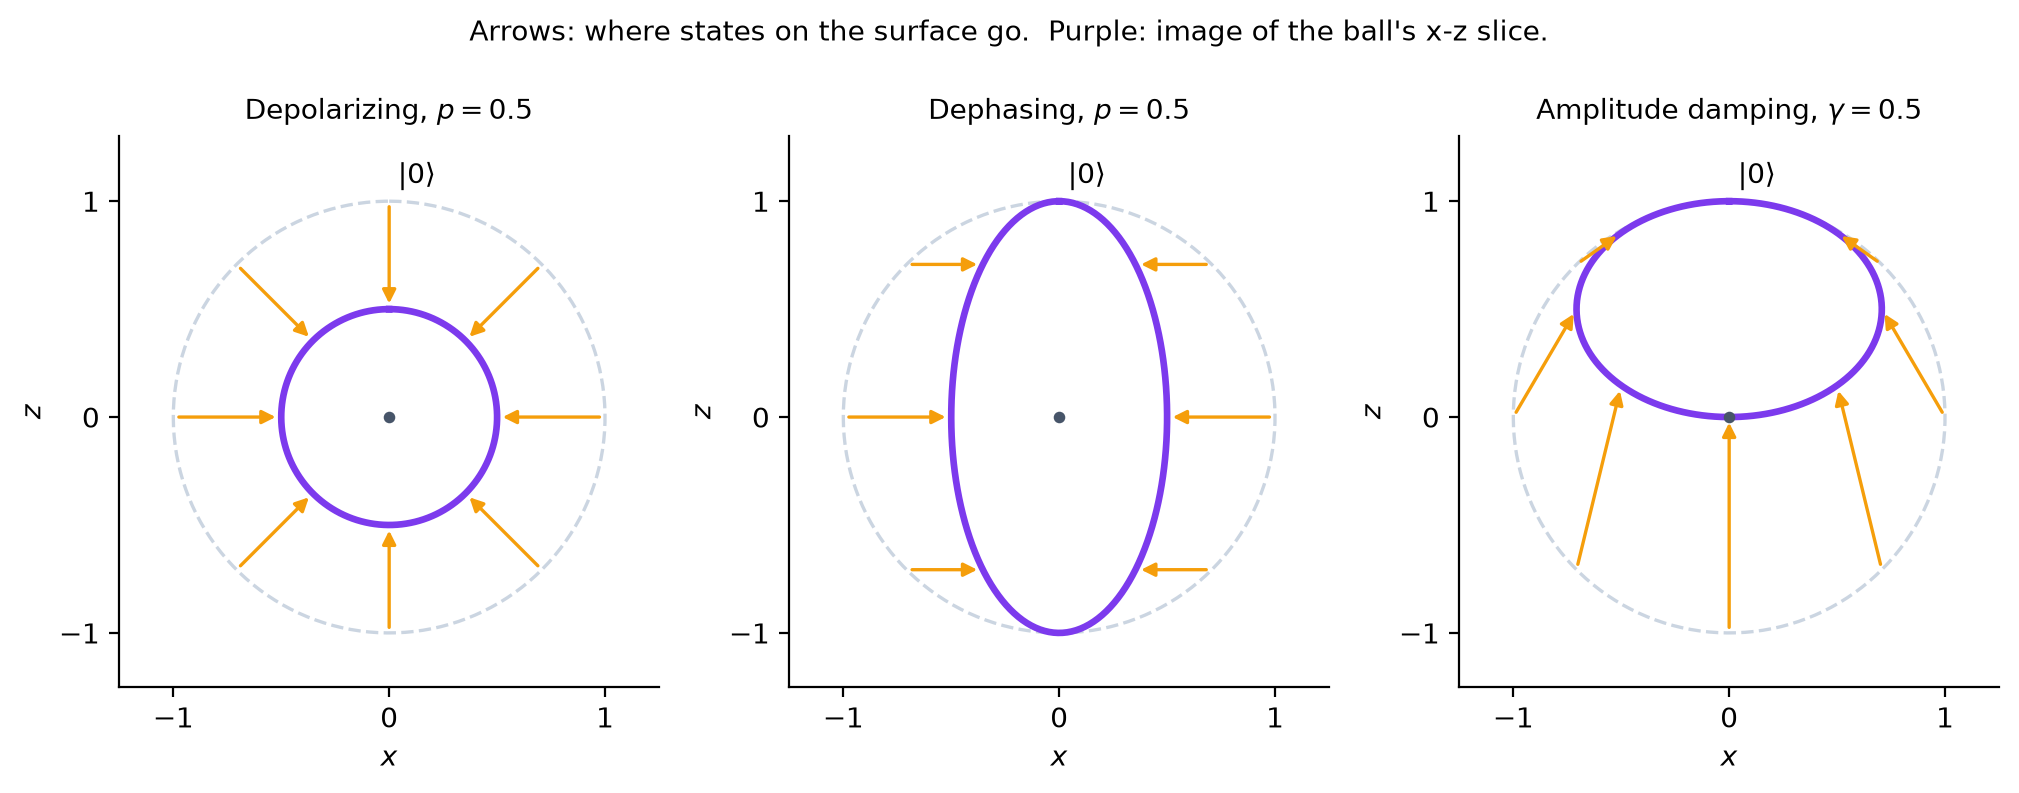

In [3]:
_show_mpl(_lessonfigs.cross_sections())

*The x-z slice of the ball (dashed) and its image (purple) at strength 0.5, with arrows from surface states to their images. Depolarizing points every arrow at the center; dephasing moves states horizontally toward the z axis; amplitude damping moves everything toward $|0\rangle$, which is its fixed point.*

:::{warning} Parameter conventions differ
Texts and software disagree on what "depolarizing with probability $p$" means. Here $p$ multiplies $I/2$, so $\vec r \mapsto (1-p)\vec r$; another common convention applies each of $X, Y, Z$ with probability $p/3$, which gives $\vec r \mapsto (1 - \tfrac{4p}{3})\vec r$. Likewise our dephasing parameter $p$ is a phase-flip probability of $p/2$ (the flip probability $q$ of [L5-10](#lesson-l5-10)). Always state the Kraus operators, not only the name.
:::

## Where Kraus operators come from

```{mermaid}
graph LR
  S[system: rho] --> U[unitary U]
  E[environment: 0] --> U
  U --> O[system: E of rho]
  U --> D[environment: traced out]
```

*The environment model: a channel is a unitary on the system and an environment that starts in a fixed state, followed by forgetting the environment (a partial trace).*

:::{prf:theorem} Kraus operators from an environment
:label: thm-l5-06-dilation
Let $U$ be a unitary on system $\otimes$ environment (system as the left factor), and let the environment start in $|0\rangle_E$. Then $\operatorname{Tr}_E\big[U(\rho \otimes |0\rangle\langle 0|_E)U^\dagger\big] = \sum_k K_k\rho K_k^\dagger$ with $K_k = \langle k|_E\,U\,|0\rangle_E$, and $\sum_k K_k^\dagger K_k = I$. Conversely, every channel arises this way from some environment and unitary [@nielsenchuang; @watrous].
:::

:::{prf:proof}
Write the partial trace over $E$ as a sum over an orthonormal basis $\{|k\rangle_E\}$: $\operatorname{Tr}_E[Y] = \sum_k (I \otimes \langle k|)\,Y\,(I \otimes |k\rangle)$, which is the definition of [L5-05](#lesson-l5-05) in operator form. Since $U(\rho \otimes |0\rangle\langle 0|)U^\dagger = U(I \otimes |0\rangle)\,\rho\,(I \otimes \langle 0|)U^\dagger$, each term is $K_k\rho K_k^\dagger$ with $K_k = (I \otimes \langle k|)U(I \otimes |0\rangle)$. Completeness: $\sum_k K_k^\dagger K_k = (I \otimes \langle 0|)U^\dagger\big(\sum_k I \otimes |k\rangle\langle k|\big)U(I \otimes |0\rangle) = (I \otimes \langle 0|)(I \otimes |0\rangle) = I$. The converse direction builds $U$ from given $K_k$ by defining $U|\psi\rangle|0\rangle = \sum_k K_k|\psi\rangle|k\rangle$, which preserves inner products because of completeness, and extending it to a unitary.
:::

$$
K_k = \langle k|_E\, U\, |0\rangle_E, \qquad U|1\rangle|0\rangle = 0.8\,|1\rangle|0\rangle + 0.6\,|0\rangle|1\rangle \;\Rightarrow\; K_0 = \begin{pmatrix}1 & 0\\ 0 & 0.8\end{pmatrix},\ K_1 = \begin{pmatrix}0 & 0.6\\ 0 & 0\end{pmatrix}
$$ (eq-l5-06-dilation)

Amplitude damping with $\gamma = 0.36$ is an excited atom that may hand its excitation to an empty field mode: $U|0\rangle|0\rangle = |0\rangle|0\rangle$ and $U|1\rangle|0\rangle = 0.8\,|1\rangle|0\rangle + 0.6\,|0\rangle|1\rangle$, since $\sqrt{1 - 0.36} = 0.8$ and $\sqrt{0.36} = 0.6$. Reading off the environment components gives [](#eq-l5-06-dilation), and the completeness sum is $K_0^\dagger K_0 + K_1^\dagger K_1 = \operatorname{diag}(1, 0.64) + \operatorname{diag}(0, 0.36) = I$.

:::{figure} ../../_static/animations/l5_06_kraus_dilation.mp4
:alt: A circuit with the system and an environment entering a unitary U, the environment then traced out; the action of U, the Kraus operators read from it, and the completeness sum adding to the identity.
:width: 100%

Amplitude damping with $\gamma = 0.36$: the Kraus operators are the environment components of one unitary, and their completeness sum $K_0^\dagger K_0 + K_1^\dagger K_1$ adds to $I$ term by term.
:::

:::{dropdown} What the animation shows
A circuit shows the system $\rho$ and the environment $|0\rangle_E$ entering a unitary $U$; the environment line ends in $\operatorname{Tr}_E$ and the system leaves as $\mathcal{E}(\rho)$. The action of $U$ is written: $U|0\rangle|0\rangle = |0\rangle|0\rangle$ and $U|1\rangle|0\rangle = 0.8\,|1\rangle|0\rangle + 0.6\,|0\rangle|1\rangle$ (amplitude damping with $\gamma = 0.36$). The rule $K_k = \langle k|_E\,U\,|0\rangle_E$ gives $K_0 = \begin{pmatrix}1 & 0\\ 0 & 0.8\end{pmatrix}$ and $K_1 = \begin{pmatrix}0 & 0.6\\ 0 & 0\end{pmatrix}$, and the channel is $\mathcal{E}(\rho) = K_0\rho K_0^\dagger + K_1\rho K_1^\dagger$. The completeness sum is written as $\operatorname{diag}(1, 0.64) + \operatorname{diag}(0, 0.36)$ and transforms into the identity, so the trace is preserved for every input. Finally two outputs appear: $\mathcal{E}(|1\rangle\langle 1|) = \operatorname{diag}(0.36, 0.64)$ and $\mathcal{E}(|+\rangle\langle +|) = \begin{pmatrix}0.68 & 0.4\\ 0.4 & 0.32\end{pmatrix}$.
:::

:::{prf:remark} Kraus operators are not unique
:label: rem-l5-06-freedom
If $L_l = \sum_k u_{lk}K_k$ for a unitary (or isometry) $u$, then $\{L_l\}$ gives the same channel, by the same computation as the ensemble theorem of [L5-05](#lesson-l5-05). For example, dephasing is given both by $\{\sqrt{1 - p/2}\,I,\ \sqrt{p/2}\,Z\}$ and by $\{\sqrt{1-p}\,I,\ \sqrt{p}\,|0\rangle\langle 0|,\ \sqrt{p}\,|1\rangle\langle 1|\}$, lists of different lengths. Different environment models can therefore produce the same channel, and the channel alone does not reveal which one is physically present.
:::

The environment model also explains how noise can be irreversible although $U$ is reversible. After $U$, the environment holds a record ($|1\rangle_E$ means the excitation left). Tracing out the environment discards that record, so the system alone cannot be restored by any channel in general.

## Positive is not enough

:::{prf:proposition} The transpose is positive but not completely positive
:label: prop-l5-06-transpose
Let $T(\rho) = \rho^T$ in the computational basis. Then $T$ is positive and trace preserving, but $(\mathrm{id} \otimes T)(|\Phi^+\rangle\langle\Phi^+|) = \tfrac12\,\mathrm{SWAP}$, which has eigenvalue $-1/2$ with eigenvector $\tfrac{1}{\sqrt2}(|01\rangle - |10\rangle)$. So $T$ is not completely positive and is not a channel.
:::

:::{prf:proof}
Positivity: $\rho^T = \bar\rho$ for Hermitian $\rho$, and $\bar\rho$ has the same (real) eigenvalues as $\rho$; the trace is unchanged. On the Bloch ball, $X^T = X$, $Y^T = -Y$, $Z^T = Z$, so $T$ acts as the mirror $(x, y, z) \mapsto (x, -y, z)$ and keeps the ball. Extension: $|\Phi^+\rangle\langle\Phi^+| = \tfrac12\sum_{i,j}|i\rangle\langle j| \otimes |i\rangle\langle j|$, so $(\mathrm{id} \otimes T)$ gives $\tfrac12\sum_{i,j}|i\rangle\langle j| \otimes |j\rangle\langle i| = \tfrac12\,\mathrm{SWAP}$, since $\mathrm{SWAP}|a\,b\rangle = |b\,a\rangle$. SWAP leaves symmetric vectors unchanged and flips the sign of the antisymmetric vector $\tfrac{1}{\sqrt2}(|01\rangle - |10\rangle)$, so $\tfrac12\,\mathrm{SWAP}$ has eigenvalues $\tfrac12, \tfrac12, \tfrac12, -\tfrac12$. A measurement that projects onto that vector would get probability $-1/2$.
:::

:::{figure} ../../_static/animations/l5_06_transpose_not_cp.mp4
:alt: Seen from above, the transpose reflects a Bloch vector across the x axis; then the 4 by 4 Bell-state matrix has each 2 by 2 block transposed, the corner entries move inward, and the eigenvalue bars show one negative value of -1/2.
:width: 100%

Alone, the transpose is a mirror of the ball. With a reference qubit, $(\mathrm{id} \otimes T)$ turns $|\Phi^+\rangle\langle\Phi^+|$ into $\tfrac12\,\mathrm{SWAP}$, whose eigenvalue $-1/2$ no physical process could produce.
:::

:::{dropdown} What the animation shows
The Bloch ball is seen from the top with the x axis drawn as a mirror line. A violet Bloch vector is reflected into an orange one: $T(\rho) = \rho^T$, $X^T = X$, $Y^T = -Y$, $Z^T = Z$, so $(x, y, z) \mapsto (x, -y, z)$. The ball goes onto itself, so $T$ maps states to states. Next the matrix $|\Phi^+\rangle\langle\Phi^+|$ appears with entries $1/2$ in its four corners and its four $2 \times 2$ blocks outlined. The step $(\mathrm{id} \otimes T)$ transposes each block and leaves the reference qubit alone: the corner entry at (00, 11) moves to (01, 10), and the one at (11, 00) moves to (10, 01). The result is $\tfrac12\,\mathrm{SWAP}$. Its eigenvalues are drawn as bars, $1/2$, $1/2$, $1/2$ and a red bar at $-1/2$, with eigenvector $\tfrac{1}{\sqrt2}(|01\rangle - |10\rangle)$. The closing line says that this negative probability means no physical process acts as $T$ on half of a pair.
:::

:::{prf:theorem} Choi's test
:label: thm-l5-06-choi
For a linear map $\mathcal{E}$ on $d \times d$ matrices, define $J(\mathcal{E}) = \sum_{i,j=0}^{d-1}|i\rangle\langle j| \otimes \mathcal{E}(|i\rangle\langle j|)$ (reference first, unnormalized). Then $\mathcal{E}$ is completely positive if and only if $J(\mathcal{E}) \ge 0$, and trace preserving if and only if $\operatorname{Tr}_{\text{out}}J(\mathcal{E}) = I$. If $J = \sum_k|v_k\rangle\langle v_k|$, the operators $K_k$ with $\langle a|K_k|i\rangle = (\langle i| \otimes \langle a|)|v_k\rangle$ are Kraus operators of $\mathcal{E}$ [@choi1975; @watrous; @nielsenchuang].
:::

:::{prf:proof}
(Sketch.) If $\mathcal{E}$ is CP, then $J = (\mathrm{id} \otimes \mathcal{E})(d\,|\Phi\rangle\langle\Phi|)$ with $|\Phi\rangle = \tfrac{1}{\sqrt d}\sum_i |i\rangle|i\rangle$ is positive. Conversely, if $J = \sum_k |v_k\rangle\langle v_k| \ge 0$ (for example its spectral decomposition), write $|v_k\rangle = \sum_i |i\rangle \otimes K_k|i\rangle$, which defines $K_k$ column by column. Then $\sum_k K_k|i\rangle\langle j|K_k^\dagger$ is the $(i, j)$ block of $J$, which is $\mathcal{E}(|i\rangle\langle j|)$; by linearity $\mathcal{E} = \sum_k K_k(\cdot)K_k^\dagger$, which is CP by Theorem [](#thm-l5-06-kraus). Finally $\operatorname{Tr}\mathcal{E}(|i\rangle\langle j|) = \delta_{ij}$ for all $i, j$ is exactly $\operatorname{Tr}_{\text{out}}J = I$.
:::

$$
J(T) = \sum_{i,j}|i\rangle\langle j| \otimes |j\rangle\langle i| = \mathrm{SWAP}, \qquad J(\mathcal{E}_{\text{AD}}) = \begin{pmatrix}1 & 0 & 0 & \sqrt{1-\gamma}\\ 0 & 0 & 0 & 0\\ 0 & 0 & \gamma & 0\\ \sqrt{1-\gamma} & 0 & 0 & 1-\gamma\end{pmatrix}
$$ (eq-l5-06-choi)

The Choi matrix of the transpose has eigenvalue $-1$, so $T$ fails the test. The Choi matrix of amplitude damping has eigenvalues $2 - \gamma$, $\gamma$, 0 and 0: it is positive, and its rank 2 says that two Kraus operators suffice. The same idea gives a test for entanglement. If $\rho_{AB} = \sum_k p_k\,\rho_A^{(k)} \otimes \rho_B^{(k)}$ is a mixture of product states, then $(\mathrm{id} \otimes T)\rho_{AB} = \sum_k p_k\,\rho_A^{(k)} \otimes (\rho_B^{(k)})^T \ge 0$. So a negative eigenvalue of the partial transpose proves entanglement [@peres1996; @watrous]. For two qubits (and for a qubit with a qutrit) the converse also holds: a positive partial transpose implies a mixture of product states [@horodecki1996].

:::{important} Why physics demands complete positivity
Any device acts locally: it cannot know whether its input qubit is entangled with something elsewhere. So the joint map on input and an untouched partner is $\mathrm{id} \otimes \mathcal{E}$, and it must send joint states to joint states. That is complete positivity. The description by a fixed map $\mathcal{E}$ also assumes that the system and the environment start uncorrelated; with initial correlations the reduced dynamics need not be a CPTP map of the input alone.
:::

## Compute it

Kraus checks with the course engine: completeness, Bloch-ball images, the worked example, the depolarizing identity of Proposition [](#prop-l5-06-dep), and two Kraus lists for one channel (compared through their Choi matrices).


In [4]:
import numpy as np
from qcai.science import (I2, X, Y, Z, dm, bloch, apply_kraus, is_cptp, choi,
                          depolarizing_kraus, dephasing_kraus, amplitude_damping_kraus)

k0, k1 = np.array([1, 0]), np.array([0, 1])
plus = np.array([1, 1]) / np.sqrt(2)

# the bit-flip channel of the text
K = [np.sqrt(0.9) * I2, np.sqrt(0.1) * X]
print('bit flip: sum K^dag K =', np.round(sum(k.conj().T @ k for k in K).real, 3).tolist(),
      ' E(|0><0|) diagonal', np.round(np.diag(apply_kraus(dm(k0), K)).real, 3))

# the three noise channels, strength 0.5: images of |0> and |+> on the Bloch ball
for name, kraus in [('depolarizing p = 0.5', depolarizing_kraus(0.5)), ('dephasing p = 0.5', dephasing_kraus(0.5)),
                    ('amp. damping g = 0.5', amplitude_damping_kraus(0.5))]:
    print(f'{name:21s} CPTP {is_cptp(kraus)}  |0> -> {np.round(bloch(apply_kraus(dm(k0), kraus)), 3)}'
          f'  |+> -> {np.round(bloch(apply_kraus(dm(plus), kraus)), 3)}')

# worked example: amplitude damping with gamma = 0.36 on |+><+|
out = apply_kraus(dm(plus), amplitude_damping_kraus(0.36))
print('AD(0.36) on |+><+| =', np.round(out.real, 3).tolist(), ' Bloch', np.round(bloch(out), 3),
      ' purity', round(np.trace(out @ out).real, 4))

# the Kraus form of depolarizing equals (1 - p) rho + p I/2, here on a complex state
rho, p = dm(np.array([0.6, 0.8j])), 0.3
print('depolarizing Kraus form = (1-p) rho + p I/2:', np.allclose(apply_kraus(rho, depolarizing_kraus(p)), (1 - p) * rho + p * I2 / 2))

# two different Kraus lists for the same dephasing channel (compared through their Choi matrices)
p = 0.4
A = dephasing_kraus(p)
B = [np.sqrt(1 - p) * I2, np.sqrt(p) * dm(k0), np.sqrt(p) * dm(k1)]
print('2 and 3 Kraus operators, one channel:', np.allclose(choi(A), choi(B)))

bit flip: sum K^dag K = [[1.0, 0.0], [0.0, 1.0]]  E(|0><0|) diagonal [0.9 0.1]
depolarizing p = 0.5  CPTP True  |0> -> [0.  0.  0.5]  |+> -> [0.5 0.  0. ]
dephasing p = 0.5     CPTP True  |0> -> [0. 0. 1.]  |+> -> [0.5 0.  0. ]
amp. damping g = 0.5  CPTP True  |0> -> [0. 0. 1.]  |+> -> [0.707 0.    0.5  ]
AD(0.36) on |+><+| = [[0.68, 0.4], [0.4, 0.32]]  Bloch [0.8  0.   0.36]  purity 0.8848
depolarizing Kraus form = (1-p) rho + p I/2: True
2 and 3 Kraus operators, one channel: True


Complete positivity in numbers: the partial transpose of $|\Phi^+\rangle\langle\Phi^+|$, Choi matrices of the transpose and of amplitude damping, Kraus operators recovered from a Choi matrix, the environment unitary of [](#eq-l5-06-dilation), and the partial-transpose test on Werner states.


In [5]:
SWAP = np.array([[1, 0, 0, 0], [0, 0, 1, 0], [0, 1, 0, 0], [0, 0, 0, 1]])

def ptranspose_B(rho):            # (id x T) on two qubits: transpose the right factor, rho_{ij,kl} -> rho_{il,kj}
    return rho.reshape(2, 2, 2, 2).transpose(0, 3, 2, 1).reshape(4, 4)

bell = np.array([1, 0, 0, 1]) / np.sqrt(2)
PT = ptranspose_B(dm(bell))
print('T alone: eigenvalues of rho^T equal those of rho:', np.allclose(np.linalg.eigvalsh(out.T), np.linalg.eigvalsh(out)))
print('(id x T)|Phi+><Phi+| = SWAP/2:', np.allclose(PT, SWAP / 2), ' eigenvalues', np.round(np.linalg.eigvalsh(PT), 3))
singlet = np.array([0, 1, -1, 0]) / np.sqrt(2)
print('<singlet| (id x T)(Phi+) |singlet> =', round(float((singlet @ PT @ singlet).real), 3))

# Choi matrices (reference qubit = left factor): channels are PSD, the transpose is not
J_T = sum(np.kron(np.outer(np.eye(2)[i], np.eye(2)[j]), np.outer(np.eye(2)[i], np.eye(2)[j]).T) for i in range(2) for j in range(2))
J_AD = choi(amplitude_damping_kraus(0.36))
print('Choi(transpose) = SWAP:', np.allclose(J_T, SWAP), ' eigenvalues', np.round(np.linalg.eigvalsh(J_T), 3))
print('Choi(amp. damping 0.36) eigenvalues', np.round(np.linalg.eigvalsh(J_AD), 3),
      ' Tr_out J =', np.round(np.einsum('iaja->ij', J_AD.reshape(2, 2, 2, 2)).real, 3).tolist())

# recover Kraus operators from the Choi matrix: J = sum_k |v_k><v_k|,  v_k[(i, a)] = (K_k)[a, i]
w, V = np.linalg.eigh(J_AD)
Ks = [np.sqrt(w[k]) * V[:, k].reshape(2, 2).T for k in range(4) if w[k] > 1e-12]
print('Kraus operators recovered from Choi:', len(Ks), ' same channel:', np.allclose(choi(Ks), J_AD))

# the environment model: U on system (x) environment, K_k = <k|_E U |0>_E
U = np.zeros((4, 4))
U[0, 0] = 1                                   # |00> -> |00>
U[:, 2] = [0, 0.6, 0.8, 0]                    # |10> -> 0.8|10> + 0.6|01>
U[:, 1] = [0, 0.8, -0.6, 0]                   # |01> -> 0.8|01> - 0.6|10> (completes a unitary)
U[3, 3] = 1                                   # |11> -> |11>
U4 = U.reshape(2, 2, 2, 2)                    # indices (s_out, e_out, s_in, e_in)
Kenv = [U4[:, k, :, 0] for k in range(2)]
print('U unitary:', np.allclose(U.T @ U, np.eye(4)), ' K_k from U equal amplitude damping:',
      all(np.allclose(a, b) for a, b in zip(Kenv, amplitude_damping_kraus(0.36))))

# partial-transpose test on Werner states v|Phi+><Phi+| + (1 - v) I/4
for v in (0.2, 1 / 3, 0.5, 1.0):
    W = v * dm(bell) + (1 - v) * np.eye(4) / 4
    print(f'v = {v:.3f}: smallest eigenvalue of the partial transpose {np.linalg.eigvalsh(ptranspose_B(W)).min():+.4f}'
          f'  (formula (1 - 3v)/4 = {(1 - 3 * v) / 4:+.4f})')

T alone: eigenvalues of rho^T equal those of rho: True
(id x T)|Phi+><Phi+| = SWAP/2: True  eigenvalues [-0.5  0.5  0.5  0.5]
<singlet| (id x T)(Phi+) |singlet> = -0.5
Choi(transpose) = SWAP: True  eigenvalues [-1.  1.  1.  1.]
Choi(amp. damping 0.36) eigenvalues [0.   0.   0.36 1.64]  Tr_out J = [[1.0, 0.0], [0.0, 1.0]]
Kraus operators recovered from Choi: 2  same channel: True
U unitary: True  K_k from U equal amplitude damping: True
v = 0.200: smallest eigenvalue of the partial transpose +0.1000  (formula (1 - 3v)/4 = +0.1000)
v = 0.333: smallest eigenvalue of the partial transpose +0.0000  (formula (1 - 3v)/4 = +0.0000)
v = 0.500: smallest eigenvalue of the partial transpose -0.1250  (formula (1 - 3v)/4 = -0.1250)
v = 1.000: smallest eigenvalue of the partial transpose -0.5000  (formula (1 - 3v)/4 = -0.5000)


## Worked example

:::{admonition} Amplitude damping on a superposition
:class: tip

Apply amplitude damping with $\gamma = 0.36$ to $|+\rangle\langle +|$. Give the output matrix, its Bloch vector and purity, and check the result against the Bloch map [](#eq-l5-06-ad).

1. Kraus operators: $K_0 = \operatorname{diag}(1, 0.8)$ and $K_1 = 0.6\,|0\rangle\langle 1|$; check $K_0^\dagger K_0 + K_1^\dagger K_1 = \operatorname{diag}(1, 0.64) + \operatorname{diag}(0, 0.36) = I$.
2. $K_0\,|+\rangle\langle +|\,K_0^\dagger = \tfrac12\begin{pmatrix}1 & 0.8\\ 0.8 & 0.64\end{pmatrix}$ and $K_1\,|+\rangle\langle +|\,K_1^\dagger = \tfrac12\begin{pmatrix}0.36 & 0\\ 0 & 0\end{pmatrix}$.
3. Sum: $\mathcal{E}(|+\rangle\langle +|) = \begin{pmatrix}0.68 & 0.4\\ 0.4 & 0.32\end{pmatrix}$, with trace 1 as required.
4. Bloch vector: $x = 2 \times 0.4 = 0.8$, $y = 0$, $z = 0.68 - 0.32 = 0.36$. The map [](#eq-l5-06-ad) with $(x, y, z) = (1, 0, 0)$ gives $(\sqrt{0.64}, 0, 0.36 + 0.64 \times 0) = (0.8, 0, 0.36)$, the same.
5. Purity: $\tfrac12(1 + 0.64 + 0.1296) = 0.8848$; directly $0.68^2 + 0.32^2 + 2 \times 0.4^2 = 0.4624 + 0.1024 + 0.32 = 0.8848$.

**Result.** $\mathcal{E}(|+\rangle\langle +|) = \begin{pmatrix}0.68 & 0.4\\ 0.4 & 0.32\end{pmatrix}$ with Bloch vector $(0.8, 0, 0.36)$ and purity $0.8848$: the state has moved toward $|0\rangle$ and lost part of its coherence.
:::

## Exercises

**1. (Core)** A bit-flip channel has flip probability 0.25: $K_0 = \sqrt{0.75}\,I$, $K_1 = \sqrt{0.25}\,X$. Check completeness, apply it to $|1\rangle\langle 1|$ and give the output diagonal in the basis order 0, 1.

:::{dropdown} Solution
$0.75I + 0.25X^2 = I$. The output is $0.75\,|1\rangle\langle 1| + 0.25\,X|1\rangle\langle 1|X = 0.75\,|1\rangle\langle 1| + 0.25\,|0\rangle\langle 0|$, so the diagonal is $(0.25, 0.75)$.
:::

**2. (Core)** Verify $\sum_k K_k^\dagger K_k = I$ for the depolarizing Kraus operators $\sqrt{1 - 3p/4}\,I$, $\sqrt{p/4}\,X$, $\sqrt{p/4}\,Y$, $\sqrt{p/4}\,Z$. Then apply the channel with $p = 0.2$ to $|0\rangle\langle 0|$ and find the purity of the output.

:::{dropdown} Solution
Each Pauli squares to $I$, so the sum is $(1 - \tfrac{3p}{4} + 3\cdot\tfrac{p}{4})I = I$. With $p = 0.2$ the output is $0.8\,|0\rangle\langle 0| + 0.2\,I/2 = \operatorname{diag}(0.9, 0.1)$, with Bloch vector $(0, 0, 0.8)$ and purity $0.81 + 0.01 = 0.82 = \tfrac12(1 + 0.64)$.
:::

**3. (Stretch)** Show that $\{\sqrt{1 - p/2}\,I,\ \sqrt{p/2}\,Z\}$ and $\{\sqrt{1-p}\,I,\ \sqrt{p}\,|0\rangle\langle 0|,\ \sqrt{p}\,|1\rangle\langle 1|\}$ define the same channel.

:::{dropdown} Solution
Both lists satisfy completeness: $(1 - \tfrac p2) + \tfrac p2 = 1$ and $(1-p)I + p(|0\rangle\langle 0| + |1\rangle\langle 1|) = I$. First list: diagonal entries are unchanged ($Z\rho Z$ has the same diagonal) and the off-diagonal entries get the factor $(1 - \tfrac p2) - \tfrac p2 = 1 - p$. Second list: $|0\rangle\langle 0|\rho|0\rangle\langle 0| + |1\rangle\langle 1|\rho|1\rangle\langle 1|$ keeps the diagonal and removes the off-diagonal, so the total keeps the diagonal and multiplies the off-diagonal by $1 - p$. The outputs agree for every $\rho$.
:::

**4. (Stretch)** For amplitude damping, show that the image of the Bloch ball is the ellipsoid with semi-axes $\sqrt{1-\gamma}$, $\sqrt{1-\gamma}$, $1-\gamma$ centered at $(0, 0, \gamma)$, and that $|0\rangle$ is the only fixed point when $0 < \gamma \le 1$.

:::{dropdown} Solution
By [](#eq-l5-06-ad) the map is $\vec r \mapsto D\vec r + (0, 0, \gamma)$ with $D = \operatorname{diag}(\sqrt{1-\gamma}, \sqrt{1-\gamma}, 1-\gamma)$; a linear map $D$ sends the unit ball to the ellipsoid with semi-axes the diagonal entries, and the shift moves its center to $(0, 0, \gamma)$. A fixed point needs $x = \sqrt{1-\gamma}\,x$ and $y = \sqrt{1-\gamma}\,y$, so $x = y = 0$ for $\gamma > 0$, and $z = \gamma + (1-\gamma)z$, so $\gamma z = \gamma$ and $z = 1$: the state $|0\rangle$.
:::

**5. (Challenge)** For the Werner state [@werner1989] $\rho_v = v\,|\Phi^+\rangle\langle\Phi^+| + (1-v)\,I/4$, compute the eigenvalues of the partial transpose $(\mathrm{id} \otimes T)\rho_v$. For which $v$ does the partial-transpose test prove entanglement?

:::{dropdown} Solution
$(\mathrm{id} \otimes T)\rho_v = v\,\tfrac12\mathrm{SWAP} + (1-v)\,I/4$, because $(\mathrm{id} \otimes T)(I/4) = I/4$. SWAP has eigenvalue $+1$ on the three symmetric vectors and $-1$ on the singlet, so the eigenvalues are $\tfrac v2 + \tfrac{1-v}{4} = \tfrac{1+v}{4}$ (three times) and $-\tfrac v2 + \tfrac{1-v}{4} = \tfrac{1-3v}{4}$. The last is negative exactly when $v > 1/3$, so $\rho_v$ is entangled for $v > 1/3$. For two qubits the converse holds as well [@horodecki1996], so $\rho_v$ is a mixture of product states for $v \le 1/3$.
:::

**6. (Challenge)** Compute the Choi matrix of amplitude damping with the convention of Theorem [](#thm-l5-06-choi), find its eigenvalues, and check $\operatorname{Tr}_{\text{out}}J = I$.

:::{dropdown} Solution
$\mathcal{E}(|0\rangle\langle 0|) = |0\rangle\langle 0|$, $\mathcal{E}(|0\rangle\langle 1|) = K_0|0\rangle\langle 1|K_0^\dagger = \sqrt{1-\gamma}\,|0\rangle\langle 1|$ (the $K_1$ term vanishes), $\mathcal{E}(|1\rangle\langle 0|) = \sqrt{1-\gamma}\,|1\rangle\langle 0|$, and $\mathcal{E}(|1\rangle\langle 1|) = \gamma\,|0\rangle\langle 0| + (1-\gamma)\,|1\rangle\langle 1|$. Placing these blocks gives the matrix in [](#eq-l5-06-choi). The middle entries give eigenvalues $0$ and $\gamma$; the outer $2 \times 2$ block $\begin{pmatrix}1 & \sqrt{1-\gamma}\\ \sqrt{1-\gamma} & 1-\gamma\end{pmatrix}$ has trace $2 - \gamma$ and determinant $0$, so eigenvalues $2 - \gamma$ and $0$. All are nonnegative, so the map is CP. $\operatorname{Tr}_{\text{out}}J$ has entries $\operatorname{Tr}\mathcal{E}(|i\rangle\langle j|) = \delta_{ij}$, so it is $I$.
:::

## Check your understanding

**1. Which condition guarantees trace preservation in a Kraus representation?**

- **A.** Every Kraus operator is unitary
- **B.** $\sum_k K_k^\dagger K_k = I$
- **C.** Every $K_k$ is Hermitian
- **D.** $\sum_k K_k = I$

:::{dropdown} Show the answer
**B. $\sum_k K_k^\dagger K_k = I$**

$\operatorname{Tr}\mathcal{E}(\rho) = \operatorname{Tr}[(\sum_k K_k^\dagger K_k)\rho]$, which equals $\operatorname{Tr}\rho$ for all $\rho$ exactly when the conjugate-product sum is $I$. Amplitude damping has a non-unitary, non-Hermitian $K_1$.
:::

**2. With the convention $\mathcal{E}_p(\rho) = (1-p)\rho + p\,I/2$, what happens to a Bloch vector $\vec r$?**

- **A.** It moves toward $|0\rangle$
- **B.** Only its z component shrinks
- **C.** It becomes $(1 - p/2)\,\vec r$
- **D.** It becomes $(1-p)\,\vec r$

:::{dropdown} Show the answer
**D. It becomes $(1-p)\,\vec r$**

$I/2$ has Bloch vector $\vec 0$ and the map is linear in $\rho$, so $\vec r \mapsto (1-p)\vec r + p\,\vec 0$: a uniform shrink.
:::

**3. Why is the transpose not a valid quantum channel, even though it maps every qubit state to a qubit state?**

- **A.** It is not linear
- **B.** It does not preserve the trace
- **C.** It changes the eigenvalues of single-qubit states
- **D.** Applied to half of $|\Phi^+\rangle$ it gives an operator with eigenvalue $-1/2$

:::{dropdown} Show the answer
**D. Applied to half of $|\Phi^+\rangle$ it gives an operator with eigenvalue $-1/2$**

$T$ is linear, trace preserving and positive, but $(\mathrm{id} \otimes T)(|\Phi^+\rangle\langle\Phi^+|) = \tfrac12\mathrm{SWAP}$ has eigenvalue $-1/2$, so it is not completely positive.
:::

**4. What is $\operatorname{Tr}_B\,|\Phi^+\rangle\langle\Phi^+|$?** *(Review of [L5-05](#lesson-l5-05))*

- **A.** $|\Phi^+\rangle\langle\Phi^+|$
- **B.** $0$
- **C.** $|0\rangle\langle 0|$
- **D.** $I/2$

:::{dropdown} Show the answer
**D. $I/2$**

The traces of the diagonal blocks are $\tfrac12$ and $\tfrac12$, and the off-diagonal blocks are traceless, so the reduced state is $I/2$.
:::

## Common misconceptions

- **"Each Kraus operator must be unitary."** Only the sum condition $\sum_k K_k^\dagger K_k = I$ is required. In amplitude damping $K_1 = \sqrt\gamma\,|0\rangle\langle 1|$ is not even invertible.
- **"A map that sends every density matrix to a density matrix is physical."** That is positivity. Physical maps must be completely positive; the transpose is positive but sends half of a Bell pair to an operator with a negative eigenvalue.
- **"The Kraus operators of a channel are unique."** Any unitary mixing of a Kraus list gives the same channel, and lists can have different lengths, as the two dephasing lists show. The Choi matrix is the unique description.
- **"Noise destroys quantum information."** In the environment model the joint evolution is unitary; information moves into correlations with the environment. It is lost to someone who has access only to the system.

:::{caution} Scope and limits
Conventions: $\rho = \tfrac12(I + \vec r\cdot\vec\sigma)$ with $|0\rangle$ at $+z$; $\mathcal{E}(\rho) = \sum_k K_k\rho K_k^\dagger$ with $\sum_k K_k^\dagger K_k = I$; extensions and Choi matrices put the reference system first, $J = \sum_{ij}|i\rangle\langle j| \otimes \mathcal{E}(|i\rangle\langle j|)$ (unnormalized); the transpose is taken in the computational basis, and the partial transpose acts on the second factor. Channel parameters follow `qcai.science` and differ from some textbooks. A fixed channel assumes no relevant initial correlation between the system and an unmodeled environment, and a single, memoryless use. The proofs of the converse halves of the environment theorem and of the two-qubit partial-transpose criterion are cited, not given. All numbers are exact calculations, not device data.
:::

:::{seealso} Where this leads
[L5-07](#lesson-l5-07) splits a channel into outcome-dependent completely positive pieces (an instrument). [L5-10](#lesson-l5-10) uses these noise channels to motivate error correction. [L6-02](#lesson-l6-02) develops the Choi representation with full conventions, and [L6-07](#lesson-l6-07) meets the same lesson again: for process matrices, as for channels, positivity alone is not enough.
:::

:::{dropdown} For instructors

**Why this lesson.** Students often accept any matrix map that keeps the Bloch ball inside itself. Seeing the transpose fail only when an entangled partner is present makes complete positivity a physical requirement rather than a technicality, and the environment model makes Kraus operators concrete [@nielsenchuang; @preskill].

**Teaching notes.**

- Before the definitions, ask whether the mirror $y \mapsto -y$ of the Bloch ball could be a physical operation; collect votes, then compute $(\mathrm{id} \otimes T)|\Phi^+\rangle\langle\Phi^+|$ together.
- Use the interactive explorer to have students predict the shape of the image (sphere, spindle, shifted ellipsoid) before pressing a button.
- Insist that every noise model is stated by its Kraus operators; the warning callout on conventions is a good discussion of reading papers.
- For the environment model, ask what the environment's state tells you after $U$, and why forgetting it is what makes the process irreversible.

**Assessment.** The worked example and the second stretch exercise test Kraus and Bloch-map computations; the Choi and Werner challenge exercises test complete positivity and its use as an entanglement test; the check questions test completeness, the depolarizing convention and the meaning of complete positivity.

**Going further.** Prove that a qubit map $\vec r \mapsto M\vec r + \vec c$ with $\vec c = 0$ and $M = \operatorname{diag}(\lambda_1, \lambda_2, \lambda_3)$ is completely positive exactly when $|\lambda_1 \pm \lambda_2| \le |1 \pm \lambda_3|$ (the Fujiwara-Algoet conditions [@fujiwara1999]), and check that the transpose, $\operatorname{diag}(1, -1, 1)$, violates them. Watrous treats Choi, Kraus and Stinespring representations in full [@watrous].

:::

## References

This lesson draws on [@nielsenchuang; @watrous; @preskill; @choi1975; @peres1996; @horodecki1996; @werner1989; @fujiwara1999].

**Further reading.**

- [@nielsenchuang]: Chapter 8 introduces quantum operations, the operator-sum (Kraus) form, the environment model, and the depolarizing, dephasing and amplitude-damping channels.
- [@watrous]: Proves the equivalence of the Choi, Kraus and Stinespring representations of channels in full generality.
- [@preskill]: The lecture notes on open systems derive the Kraus form from a unitary on system and environment.

**Next:** [L5-07 · Measurements and instruments](#lesson-l5-07)
